In [60]:
import pandas as pd
import numpy as np

# Load the exact time-based train/test split
train_df = pd.read_csv("../data/train_data.csv")
test_df = pd.read_csv("../data/test_data.csv")

# Remove target and time-helper columns from model inputs
X_train = train_df.drop(
    columns=["IS_CANCELED", "YEAR", "MONTH_NUM"]
)
y_train = train_df["IS_CANCELED"]

X_test = test_df.drop(
    columns=["IS_CANCELED", "YEAR", "MONTH_NUM"]
)
y_test = test_df["IS_CANCELED"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (61840, 81)
X_test: (25556, 81)
y_train: (61840,)
y_test: (25556,)


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Logistic Regression with feature scaling
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

# Predictions
y_pred = lr_pipeline.predict(X_test)
y_proba = lr_pipeline.predict_proba(X_test)[:, 1]

# Metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("Logistic Regression — Scaled Baseline")
print("-" * 45)
print(f"Precision : {precision:.3f}")
print(f"Recall    : {recall:.3f}")
print(f"F1 Score  : {f1:.3f}")
print(f"ROC-AUC   : {auc:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression — Scaled Baseline
---------------------------------------------
Precision : 0.457
Recall    : 0.902
F1 Score  : 0.607
ROC-AUC   : 0.792

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.47      0.62     17067
           1       0.46      0.90      0.61      8489

    accuracy                           0.61     25556
   macro avg       0.68      0.68      0.61     25556
weighted avg       0.76      0.61      0.61     25556


Confusion Matrix:
[[7978 9089]
 [ 836 7653]]


In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Logistic Regression baseline
lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr.fit(X_train, y_train)

# Predictions
y_pred = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:, 1]

# Evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("Logistic Regression Baseline")
print("-" * 35)
print(f"Precision : {precision:.3f}")
print(f"Recall    : {recall:.3f}")
print(f"F1 Score  : {f1:.3f}")
print(f"ROC-AUC   : {auc:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Baseline
-----------------------------------
Precision : 0.499
Recall    : 0.784
F1 Score  : 0.609
ROC-AUC   : 0.774

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.61      0.71     17067
           1       0.50      0.78      0.61      8489

    accuracy                           0.67     25556
   macro avg       0.67      0.70      0.66     25556
weighted avg       0.73      0.67      0.68     25556


Confusion Matrix:
[[10373  6694]
 [ 1834  6655]]


lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Predictions
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

# Metrics
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_proba)

print("Random Forest")
print("-" * 35)
print(f"Precision : {rf_precision:.3f}")
print(f"Recall    : {rf_recall:.3f}")
print(f"F1 Score  : {rf_f1:.3f}")
print(f"ROC-AUC   : {rf_auc:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest
-----------------------------------
Precision : 0.523
Recall    : 0.766
F1 Score  : 0.621
ROC-AUC   : 0.787

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.65      0.74     17067
           1       0.52      0.77      0.62      8489

    accuracy                           0.69     25556
   macro avg       0.69      0.71      0.68     25556
weighted avg       0.74      0.69      0.70     25556


Confusion Matrix:
[[11133  5934]
 [ 1987  6502]]


In [64]:
pip install mlflow

You should consider upgrading via the 'd:\TravelIQ\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [65]:
import mlflow
import mlflow.sklearn

print("MLflow version:", mlflow.__version__)

MLflow version: 2.17.2


In [66]:
import mlflow
import mlflow.sklearn

# Create/select TravelIQ experiment
mlflow.set_experiment("TravelIQ_Cancellation_Prediction")

print("MLflow experiment configured successfully.")

MLflow experiment configured successfully.


In [67]:
with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    # Log model parameters
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("max_iter", 2000)
    mlflow.log_param("scaler", "StandardScaler")
    mlflow.log_param("features", X_train.shape[1])

    # Log evaluation metrics
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("roc_auc", auc)

    # Log trained model
    mlflow.sklearn.log_model(
        lr_pipeline,
        "logistic_regression_model"
    )

    print("Logistic Regression run logged successfully.")
    print("Run ID:", mlflow.active_run().info.run_id)

2026/10/09 23:29:16 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Logistic Regression run logged successfully.
Run ID: 623e7d1c01e84fc39865e00720767593


In [68]:
with mlflow.start_run(run_name="Random_Forest"):

    # Log model parameters
    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 12)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("features", X_train.shape[1])

    # Log evaluation metrics
    mlflow.log_metric("precision", rf_precision)
    mlflow.log_metric("recall", rf_recall)
    mlflow.log_metric("f1_score", rf_f1)
    mlflow.log_metric("roc_auc", rf_auc)

    # Log trained model
    mlflow.sklearn.log_model(
        rf,
        "random_forest_model"
    )

    print("Random Forest run logged successfully.")
    print("Run ID:", mlflow.active_run().info.run_id)

2026/10/09 23:29:19 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Random Forest run logged successfully.
Run ID: 2a2c07e62a874a8eb52e525a8846a4bf


In [69]:
import mlflow

mlflow.set_tracking_uri("file:///D:/TravelIQ/mlruns")

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: file:///D:/TravelIQ/mlruns


In [70]:
mlflow.set_experiment("TravelIQ_Cancellation_Prediction")

print("Experiment:", mlflow.get_experiment_by_name(
    "TravelIQ_Cancellation_Prediction"
))

Experiment: <Experiment: artifact_location='file:///D:/TravelIQ/mlruns/177730327616754753', creation_time=1791140546995, experiment_id='177730327616754753', last_update_time=1791140546995, lifecycle_stage='active', name='TravelIQ_Cancellation_Prediction', tags={}>


In [71]:
import mlflow

print("Tracking URI:")
print(mlflow.get_tracking_uri())

print("\nExperiment:")
exp = mlflow.get_experiment_by_name("TravelIQ_Cancellation_Prediction")
print(exp)

Tracking URI:
file:///D:/TravelIQ/mlruns

Experiment:
<Experiment: artifact_location='file:///D:/TravelIQ/mlruns/177730327616754753', creation_time=1791140546995, experiment_id='177730327616754753', last_update_time=1791140546995, lifecycle_stage='active', name='TravelIQ_Cancellation_Prediction', tags={}>


In [72]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("file:///D:/TravelIQ/mlruns")
mlflow.set_experiment("TravelIQ_Cancellation_Prediction")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment ID:", mlflow.get_experiment_by_name(
    "TravelIQ_Cancellation_Prediction"
).experiment_id)

Tracking URI: file:///D:/TravelIQ/mlruns
Experiment ID: 177730327616754753


In [73]:
with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("max_iter", 2000)
    mlflow.log_param("scaler", "StandardScaler")
    mlflow.log_param("features", X_train.shape[1])

    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("roc_auc", auc)

    mlflow.sklearn.log_model(
        lr_pipeline,
        "logistic_regression_model"
    )

    print("Logistic Regression logged successfully.")

2026/10/09 23:29:22 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Logistic Regression logged successfully.


In [74]:
with mlflow.start_run(run_name="Random_Forest"):

    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 12)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("features", X_train.shape[1])

    mlflow.log_metric("precision", rf_precision)
    mlflow.log_metric("recall", rf_recall)
    mlflow.log_metric("f1_score", rf_f1)
    mlflow.log_metric("roc_auc", rf_auc)

    mlflow.sklearn.log_model(
        rf,
        "random_forest_model"
    )

    print("Random Forest logged successfully.")

2026/10/09 23:29:26 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Random Forest logged successfully.


In [75]:
!pip install xgboost

You should consider upgrading via the 'd:\traveliq\.venv\scripts\python.exe -m pip install --upgrade pip' command.


In [76]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 2.1.4


In [77]:
import pandas as pd

# Load saved train/test datasets
train_df = pd.read_csv("../data/train_data.csv")
test_df = pd.read_csv("../data/test_data.csv")

# Separate features and target
X_train = train_df.drop(columns=["IS_CANCELED", "YEAR", "MONTH_NUM"])
y_train = train_df["IS_CANCELED"]

X_test = test_df.drop(columns=["IS_CANCELED", "YEAR", "MONTH_NUM"])
y_test = test_df["IS_CANCELED"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (61840, 81)
X_test: (25556, 81)
y_train: (61840,)
y_test: (25556,)


In [78]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import mlflow
import mlflow.sklearn

# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Metrics
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

print("XGBoost")
print("-----------------------------------")
print(f"Precision : {precision_xgb:.3f}")
print(f"Recall    : {recall_xgb:.3f}")
print(f"F1 Score  : {f1_xgb:.3f}")
print(f"ROC-AUC   : {auc_xgb:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost
-----------------------------------
Precision : 0.659
Recall    : 0.514
F1 Score  : 0.578
ROC-AUC   : 0.802

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.82     17067
           1       0.66      0.51      0.58      8489

    accuracy                           0.75     25556
   macro avg       0.72      0.69      0.70     25556
weighted avg       0.74      0.75      0.74     25556

Confusion Matrix:
[[14805  2262]
 [ 4123  4366]]


In [79]:
with mlflow.start_run(run_name="XGBoost"):

    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("subsample", 0.8)
    mlflow.log_param("colsample_bytree", 0.8)

    mlflow.log_metric("precision", precision_xgb)
    mlflow.log_metric("recall", recall_xgb)
    mlflow.log_metric("f1_score", f1_xgb)
    mlflow.log_metric("auc_roc", auc_xgb)

    mlflow.sklearn.log_model(xgb_model, "model")

print("XGBoost run logged successfully.")

2026/10/09 23:29:37 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


XGBoost run logged successfully.


In [80]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression (Scaled)",
        "Random Forest",
        "XGBoost"
    ],
    "Precision": [
        0.499,
        0.457,
        0.523,
        precision_xgb
    ],
    "Recall": [
        0.784,
        0.902,
        0.766,
        recall_xgb
    ],
    "F1 Score": [
        0.609,
        0.607,
        0.621,
        f1_xgb
    ],
    "ROC-AUC": [
        0.774,
        0.792,
        0.787,
        auc_xgb
    ]
})

display(comparison.sort_values("F1 Score", ascending=False))

,Model,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.523000,0.766000,0.621000,0.787000
0,Logistic Regression,0.499000,0.784000,0.609000,0.774000
1,Logistic Regression (Scaled),0.457000,0.902000,0.607000,0.792000
3,XGBoost,0.658721,0.514313,0.577628,0.801955


In [81]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [82]:
# Random Forest Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Features:")
display(feature_importance.head(20))

Top 20 Features:


,Feature,Importance
0,LEAD_TIME,0.141710
1,REQUIRED_CAR_PARKING_SPACES,0.105553
2,MARKET_SEGMENT_Online TA,0.084020
3,MARKET_SEGMENT_Offline TA/TO,0.043620
4,TOTAL_OF_SPECIAL_REQUESTS,0.043608
5,PREVIOUS_CANCELLATIONS,0.040851
6,HAS_SPECIAL_REQUESTS,0.037112
7,ADR,0.035657
8,TOTAL_SPECIAL_REQUESTS,0.033992
9,HAS_PREVIOUS_CANCELLATIONS,0.033718


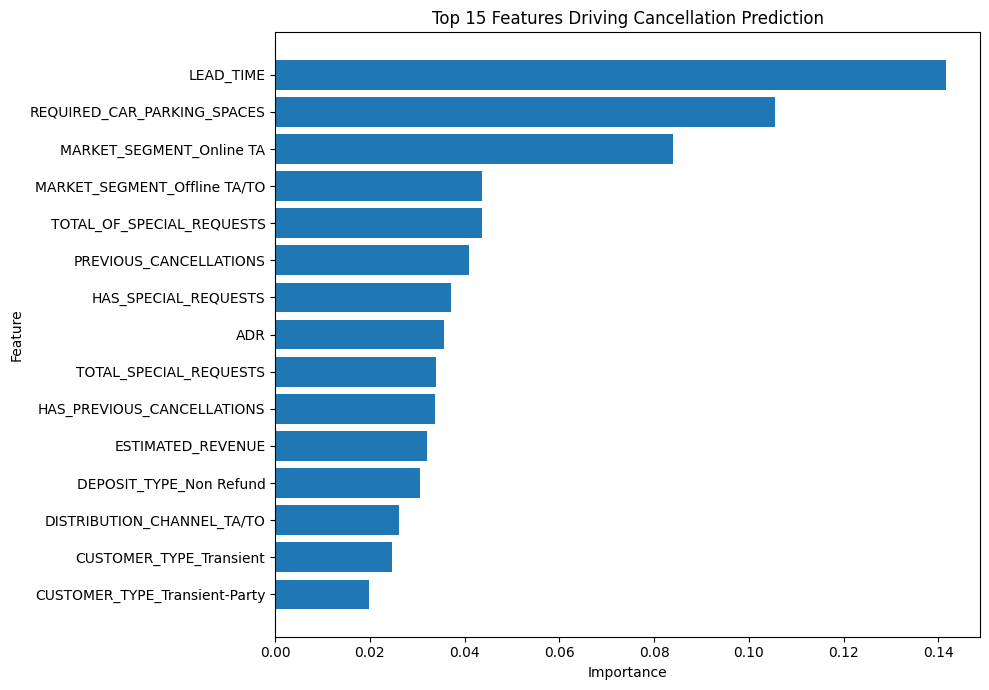

In [83]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Driving Cancellation Prediction")
plt.tight_layout()
plt.show()

In [84]:
print("Random Forest features:", rf.n_features_in_)
print("Training features:", X_train.shape[1])

Random Forest features: 81
Training features: 81


In [85]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/final_random_forest.pkl"

joblib.dump(rf, model_path)

print("Final Random Forest model saved successfully!")
print("Path:", model_path)

Final Random Forest model saved successfully!
Path: ../models/final_random_forest.pkl


In [86]:
import joblib
import pandas as pd

# Load saved Random Forest model
model_path = "../models/final_random_forest.pkl"

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Saved model loaded successfully!
Model type: RandomForestClassifier


In [87]:
# Make predictions using the saved model

y_pred_saved = loaded_model.predict(X_test)
y_proba_saved = loaded_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_saved))
print("First 10 predictions:", y_pred_saved[:10])
print("First 10 probabilities:", y_proba_saved[:10])

Predictions generated successfully!
Number of predictions: 25556
First 10 predictions: [1 1 1 1 1 1 1 1 1 1]
First 10 probabilities: [0.94683255 0.80287766 0.83690728 0.55778079 0.57449869 0.77043992
 0.81109219 0.76698375 0.52655624 0.82512537]


In [88]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    accuracy_score
)

precision = precision_score(y_test, y_pred_saved)
recall = recall_score(y_test, y_pred_saved)
f1 = f1_score(y_test, y_pred_saved)
auc = roc_auc_score(y_test, y_proba_saved)
accuracy = accuracy_score(y_test, y_pred_saved)

print("Saved Random Forest Performance")
print("--------------------------------")
print(f"Accuracy  : {accuracy:.3f}")
print(f"Precision : {precision:.3f}")
print(f"Recall    : {recall:.3f}")
print(f"F1 Score  : {f1:.3f}")
print(f"ROC-AUC   : {auc:.3f}")

Saved Random Forest Performance
--------------------------------
Accuracy  : 0.690
Precision : 0.523
Recall    : 0.766
F1 Score  : 0.621
ROC-AUC   : 0.787


Confusion Matrix:
[[11133  5934]
 [ 1987  6502]]


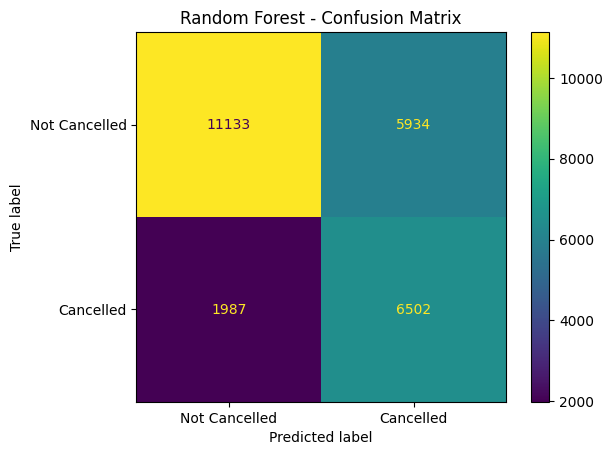

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_saved)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Cancelled", "Cancelled"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [90]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba_saved >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)

,Threshold,Precision,Recall,F1 Score
0,0.30,0.425001,0.951584,0.587576
1,0.35,0.448447,0.923784,0.603788
2,0.40,0.469179,0.885852,0.613452
3,0.45,0.489998,0.839675,0.618857
4,0.50,0.522837,0.765932,0.621458
5,0.55,0.585274,0.624573,0.604285
6,0.60,0.639087,0.484981,0.551470


In [91]:
# Final TravelIQ cancellation risk predictions

final_predictions = test_df.copy()

final_predictions["CANCELLATION_PROBABILITY"] = y_proba_saved
final_predictions["PREDICTED_CANCELLATION"] = y_pred_saved

# Risk categories
final_predictions["RISK_CATEGORY"] = pd.cut(
    final_predictions["CANCELLATION_PROBABILITY"],
    bins=[0, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True
)

print("Final prediction dataset created.")
print("Shape:", final_predictions.shape)

display(
    final_predictions[
        ["CANCELLATION_PROBABILITY",
         "PREDICTED_CANCELLATION",
         "RISK_CATEGORY"]
    ].head(10)
)

Final prediction dataset created.
Shape: (25556, 87)


,CANCELLATION_PROBABILITY,PREDICTED_CANCELLATION,RISK_CATEGORY
0,0.946833,1,High Risk
1,0.802878,1,High Risk
2,0.836907,1,High Risk
3,0.557781,1,Medium Risk
4,0.574499,1,Medium Risk
5,0.770440,1,High Risk
6,0.811092,1,High Risk
7,0.766984,1,High Risk
8,0.526556,1,Medium Risk
9,0.825125,1,High Risk


In [92]:
risk_distribution = (
    final_predictions["RISK_CATEGORY"]
    .value_counts()
    .sort_index()
)

print("TravelIQ Risk Distribution")
print("--------------------------")
display(risk_distribution)

# Percentage distribution
risk_percentage = (
    final_predictions["RISK_CATEGORY"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
    .round(2)
)

print("Risk Percentage:")
display(risk_percentage)

TravelIQ Risk Distribution
--------------------------


RISK_CATEGORY
Low Risk        6549
Medium Risk    12565
High Risk       6442
Name: count, dtype: int64

Risk Percentage:


RISK_CATEGORY
Low Risk       25.63
Medium Risk    49.17
High Risk      25.21
Name: proportion, dtype: float64

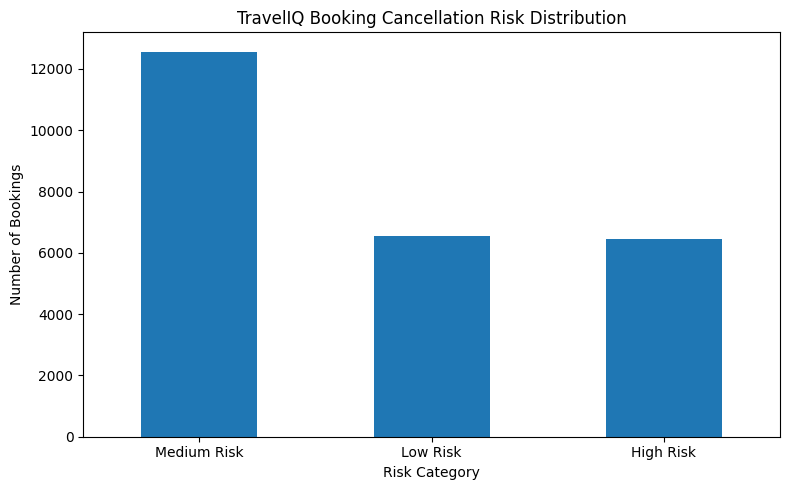

In [93]:
import matplotlib.pyplot as plt

risk_counts = final_predictions["RISK_CATEGORY"].value_counts()

plt.figure(figsize=(8, 5))
risk_counts.plot(kind="bar")

plt.title("TravelIQ Booking Cancellation Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [94]:
# Analyze high-risk bookings

high_risk = final_predictions[
    final_predictions["RISK_CATEGORY"] == "High Risk"
].copy()

print("High-Risk Bookings:", len(high_risk))

print("\nAverage Lead Time:")
print(round(high_risk["LEAD_TIME"].mean(), 2))

print("\nAverage ADR:")
print(round(high_risk["ADR"].mean(), 2))

print("\nAverage Total Stay Nights:")
print(round(high_risk["TOTAL_STAY_NIGHTS"].mean(), 2))

print("\nPrevious Cancellations:")
print(round(high_risk["PREVIOUS_CANCELLATIONS"].mean(), 2))

print("\nMarket Segment:")
display(high_risk["MARKET_SEGMENT"].value_counts().head(10))

High-Risk Bookings: 6442

Average Lead Time:
139.01

Average ADR:
137.5

Average Total Stay Nights:
4.39

Previous Cancellations:
0.0

Market Segment:


KeyError: 'MARKET_SEGMENT'

In [ ]:
print("High-Risk Bookings:", len(high_risk))

print("\nAverage Lead Time:")
print(round(high_risk["LEAD_TIME"].mean(), 2))

print("\nAverage ADR:")
print(round(high_risk["ADR"].mean(), 2))

print("\nAverage Total Stay Nights:")
print(round(high_risk["TOTAL_STAY_NIGHTS"].mean(), 2))

print("\nAverage Previous Cancellations:")
print(round(high_risk["PREVIOUS_CANCELLATIONS"].mean(), 2))

print("\nHigh-Risk Market Segment Indicators:")

market_segment_cols = [
    col for col in high_risk.columns
    if col.startswith("MARKET_SEGMENT_")
]

for col in market_segment_cols:
    print(
        col,
        ":", 
        int(high_risk[col].sum()),
        f"({high_risk[col].mean() * 100:.2f}%)"
    )

High-Risk Bookings: 6442

Average Lead Time:
139.01

Average ADR:
137.5

Average Total Stay Nights:
4.39

Average Previous Cancellations:
0.0

High-Risk Market Segment Indicators:
MARKET_SEGMENT_Complementary : 0 (0.00%)
MARKET_SEGMENT_Corporate : 5 (0.08%)
MARKET_SEGMENT_Direct : 35 (0.54%)
MARKET_SEGMENT_Groups : 184 (2.86%)
MARKET_SEGMENT_Offline TA/TO : 83 (1.29%)
MARKET_SEGMENT_Online TA : 6135 (95.23%)
MARKET_SEGMENT_Undefined : 0 (0.00%)


In [ ]:
# High-risk bookings by customer type

customer_type_cols = [
    col for col in high_risk.columns
    if col.startswith("CUSTOMER_TYPE_")
]

print("High-Risk Customer Type Indicators")
print("-----------------------------------")

for col in customer_type_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

High-Risk Customer Type Indicators
-----------------------------------
CUSTOMER_TYPE_Group: 0 (0.00%)
CUSTOMER_TYPE_Transient: 6434 (99.88%)
CUSTOMER_TYPE_Transient-Party: 8 (0.12%)


In [ ]:
# High-risk bookings by deposit type

deposit_cols = [
    col for col in high_risk.columns
    if col.startswith("DEPOSIT_TYPE_")
]

print("High-Risk Deposit Type Indicators")
print("---------------------------------")

for col in deposit_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

High-Risk Deposit Type Indicators
---------------------------------
DEPOSIT_TYPE_Non Refund: 269 (4.18%)
DEPOSIT_TYPE_Refundable: 4 (0.06%)


In [ ]:
# Estimated revenue exposure from high-risk bookings

high_risk_revenue = high_risk["ESTIMATED_REVENUE"].sum()
average_high_risk_revenue = high_risk["ESTIMATED_REVENUE"].mean()

print("High-Risk Revenue Exposure")
print("--------------------------")
print(f"Total Estimated Revenue : {high_risk_revenue:,.2f}")
print(f"Average Revenue/Booking : {average_high_risk_revenue:,.2f}")

High-Risk Revenue Exposure
--------------------------
Total Estimated Revenue : 3,937,088.65
Average Revenue/Booking : 611.16


In [ ]:
import pandas as pd
import joblib

# ==========================================
# 1. Load test dataset
# ==========================================

test_df = pd.read_csv("../data/test_data.csv")

print("Test data loaded successfully!")
print("Test shape:", test_df.shape)


# ==========================================
# 2. Prepare X_test
# ==========================================

X_test = test_df.drop(
    columns=["IS_CANCELED", "YEAR", "MONTH_NUM"],
    errors="ignore"
)

print("X_test shape:", X_test.shape)


# ==========================================
# 3. Load saved Random Forest model
# ==========================================

model_path = "../models/final_random_forest.pkl"

loaded_model = joblib.load(model_path)

print("Random Forest model loaded successfully!")


# ==========================================
# 4. Generate predictions
# ==========================================

y_pred_saved = loaded_model.predict(X_test)

y_proba_saved = loaded_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_saved))


# ==========================================
# 5. Create final prediction dataset
# ==========================================

final_prediction_df = test_df.copy()

final_prediction_df["CANCELLATION_PROBABILITY"] = y_proba_saved
final_prediction_df["PREDICTED_CANCELLATION"] = y_pred_saved


# ==========================================
# 6. Create risk categories
# ==========================================

final_prediction_df["RISK_CATEGORY"] = pd.cut(
    final_prediction_df["CANCELLATION_PROBABILITY"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)


# ==========================================
# 7. Create high-risk dataset
# ==========================================

high_risk = final_prediction_df[
    final_prediction_df["RISK_CATEGORY"] == "High Risk"
].copy()

print("\nFinal prediction dataset created.")
print("Shape:", final_prediction_df.shape)

print("\nHigh-Risk Bookings:", len(high_risk))

display(
    final_prediction_df[
        [
            "CANCELLATION_PROBABILITY",
            "PREDICTED_CANCELLATION",
            "RISK_CATEGORY"
        ]
    ].head(10)
)

Test data loaded successfully!
Test shape: (25556, 84)
X_test shape: (25556, 81)
Random Forest model loaded successfully!
Predictions generated successfully!
Number of predictions: 25556

Final prediction dataset created.
Shape: (25556, 87)

High-Risk Bookings: 6442


,CANCELLATION_PROBABILITY,PREDICTED_CANCELLATION,RISK_CATEGORY
0,0.946833,1,High Risk
1,0.802878,1,High Risk
2,0.836907,1,High Risk
3,0.557781,1,Medium Risk
4,0.574499,1,Medium Risk
5,0.770440,1,High Risk
6,0.811092,1,High Risk
7,0.766984,1,High Risk
8,0.526556,1,Medium Risk
9,0.825125,1,High Risk


In [ ]:
import os

output_path = "../data/final_predictions.csv"
os.makedirs("../data", exist_ok=True)

final_prediction_df.to_csv(output_path, index=False)

print("Predictions saved successfully!")
print("File:", output_path)
print("Total predictions:", len(final_prediction_df))
print(final_prediction_df.head())

Predictions saved successfully!
File: ../data/final_predictions.csv
Total predictions: 25556
   IS_CANCELED  LEAD_TIME  ARRIVAL_DATE_YEAR  ARRIVAL_DATE_WEEK_NUMBER  \
0            1        601               2017                         9   
1            1         98               2017                         9   
2            1         28               2017                         9   
3            1         79               2017                         9   
4            1        145               2017                         9   

   ARRIVAL_DATE_DAY_OF_MONTH  STAYS_IN_WEEKEND_NIGHTS  STAYS_IN_WEEK_NIGHTS  \
0                          2                        0                     1   
1                          2                        0                     2   
2                          2                        0                     3   
3                          2                        0                     3   
4                          2                        0              

In [ ]:
# Recreate high-risk bookings from the final prediction dataset

high_risk = final_prediction_df[
    final_prediction_df["RISK_CATEGORY"] == "High Risk"
].copy()

print("High-Risk Bookings:", len(high_risk))

# Lead-time buckets
high_risk["LEAD_TIME_GROUP"] = pd.cut(
    high_risk["LEAD_TIME"],
    bins=[-1, 30, 60, 90, 180, float("inf")],
    labels=[
        "0-30 days",
        "31-60 days",
        "61-90 days",
        "91-180 days",
        "180+ days"
    ]
)

lead_time_analysis = (
    high_risk["LEAD_TIME_GROUP"]
    .value_counts()
    .sort_index()
)

print("\nHigh-Risk Bookings by Lead Time")
print("--------------------------------")
display(lead_time_analysis)

High-Risk Bookings: 6442

High-Risk Bookings by Lead Time
--------------------------------


LEAD_TIME_GROUP
0-30 days       695
31-60 days      817
61-90 days      781
91-180 days    2218
180+ days      1931
Name: count, dtype: int64

In [ ]:
# Find the dataframe containing our final prediction data

import pandas as pd

dataframe_candidates = []

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        if "RISK_CATEGORY" in obj.columns and "LEAD_TIME" in obj.columns:
            dataframe_candidates.append(name)

print("Matching DataFrames:", dataframe_candidates)

Matching DataFrames: ['final_predictions', 'high_risk', 'final_prediction_df']


In [ ]:
# High-risk bookings: Lead Time Percentage Analysis

lead_time_percentage = (
    high_risk["LEAD_TIME_GROUP"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("High-Risk Bookings by Lead Time (%)")
print("------------------------------------")
display(lead_time_percentage.round(2))

High-Risk Bookings by Lead Time (%)
------------------------------------


LEAD_TIME_GROUP
0-30 days      10.79
31-60 days     12.68
61-90 days     12.12
91-180 days    34.43
180+ days      29.98
Name: proportion, dtype: float64

In [ ]:
# High-Risk Customer & Deposit Type Analysis

print("High-Risk Customer Type")
print("-----------------------")

customer_type_cols = [
    col for col in high_risk.columns
    if col.startswith("CUSTOMER_TYPE_")
]

for col in customer_type_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    print(f"{col}: {count} ({percentage:.2f}%)")


print("\nHigh-Risk Deposit Type")
print("----------------------")

deposit_type_cols = [
    col for col in high_risk.columns
    if col.startswith("DEPOSIT_TYPE_")
]

for col in deposit_type_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    print(f"{col}: {count} ({percentage:.2f}%)")

High-Risk Customer Type
-----------------------
CUSTOMER_TYPE_Group: 0 (0.00%)
CUSTOMER_TYPE_Transient: 6434 (99.88%)
CUSTOMER_TYPE_Transient-Party: 8 (0.12%)

High-Risk Deposit Type
----------------------
DEPOSIT_TYPE_Non Refund: 269 (4.18%)
DEPOSIT_TYPE_Refundable: 4 (0.06%)


In [ ]:
# High-Risk Revenue Exposure

high_risk_revenue = high_risk["ESTIMATED_REVENUE"].sum()
average_high_risk_revenue = high_risk["ESTIMATED_REVENUE"].mean()

print("High-Risk Revenue Exposure")
print("--------------------------")
print(f"Total Estimated Revenue at Risk: {high_risk_revenue:,.2f}")
print(f"Average Revenue per High-Risk Booking: {average_high_risk_revenue:,.2f}")

High-Risk Revenue Exposure
--------------------------
Total Estimated Revenue at Risk: 3,937,088.65
Average Revenue per High-Risk Booking: 611.16


In [ ]:
# High-Risk Market Segment Analysis

market_segment_cols = [
    col for col in high_risk.columns
    if col.startswith("MARKET_SEGMENT_")
]

print("High-Risk Market Segment Indicators")
print("-----------------------------------")

for col in market_segment_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    
    print(f"{col}: {count} ({percentage:.2f}%)")

High-Risk Market Segment Indicators
-----------------------------------
MARKET_SEGMENT_Complementary: 0 (0.00%)
MARKET_SEGMENT_Corporate: 5 (0.08%)
MARKET_SEGMENT_Direct: 35 (0.54%)
MARKET_SEGMENT_Groups: 184 (2.86%)
MARKET_SEGMENT_Offline TA/TO: 83 (1.29%)
MARKET_SEGMENT_Online TA: 6135 (95.23%)
MARKET_SEGMENT_Undefined: 0 (0.00%)


In [ ]:
# TravelIQ - Final Business Insights

print("=" * 55)
print("        TRAVELIQ - FINAL BUSINESS INSIGHTS")
print("=" * 55)

print(f"\n1. High-Risk Bookings        : {len(high_risk):,}")

print(f"2. Revenue at Risk           : "
      f"{high_risk['ESTIMATED_REVENUE'].sum():,.2f}")

print(f"3. Avg Revenue / Booking     : "
      f"{high_risk['ESTIMATED_REVENUE'].mean():,.2f}")

print(f"4. Avg Lead Time             : "
      f"{high_risk['LEAD_TIME'].mean():.2f} days")

print(f"5. Avg ADR                   : "
      f"{high_risk['ADR'].mean():.2f}")

print(f"6. Avg Stay                  : "
      f"{high_risk['TOTAL_STAY_NIGHTS'].mean():.2f} nights")

print("\n7. TOP MARKET SEGMENT")
print("----------------------")

market_segment_summary = []

for col in market_segment_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    
    market_segment_summary.append(
        (col.replace("MARKET_SEGMENT_", ""), count, percentage)
    )

market_segment_summary = sorted(
    market_segment_summary,
    key=lambda x: x[1],
    reverse=True
)

for segment, count, percentage in market_segment_summary:
    print(f"{segment}: {count:,} ({percentage:.2f}%)")


print("\n8. LEAD-TIME DISTRIBUTION")
print("-------------------------")

display(
    high_risk["LEAD_TIME_GROUP"]
    .value_counts()
    .sort_index()
)


print("\n9. CUSTOMER TYPE")
print("----------------")

for col in customer_type_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    
    if count > 0:
        print(f"{col.replace('CUSTOMER_TYPE_', '')}: "
              f"{count:,} ({percentage:.2f}%)")


print("\n10. DEPOSIT TYPE")
print("----------------")

for col in deposit_type_cols:
    count = int(high_risk[col].sum())
    percentage = high_risk[col].mean() * 100
    
    if count > 0:
        print(f"{col.replace('DEPOSIT_TYPE_', '')}: "
              f"{count:,} ({percentage:.2f}%)")

print("\n" + "=" * 55)
print("Business analysis completed successfully!")
print("=" * 55)

        TRAVELIQ - FINAL BUSINESS INSIGHTS

1. High-Risk Bookings        : 6,442
2. Revenue at Risk           : 3,937,088.65
3. Avg Revenue / Booking     : 611.16
4. Avg Lead Time             : 139.01 days
5. Avg ADR                   : 137.50
6. Avg Stay                  : 4.39 nights

7. TOP MARKET SEGMENT
----------------------
Online TA: 6,135 (95.23%)
Groups: 184 (2.86%)
Offline TA/TO: 83 (1.29%)
Direct: 35 (0.54%)
Corporate: 5 (0.08%)
Complementary: 0 (0.00%)
Undefined: 0 (0.00%)

8. LEAD-TIME DISTRIBUTION
-------------------------


LEAD_TIME_GROUP
0-30 days       695
31-60 days      817
61-90 days      781
91-180 days    2218
180+ days      1931
Name: count, dtype: int64


9. CUSTOMER TYPE
----------------
Transient: 6,434 (99.88%)
Transient-Party: 8 (0.12%)

10. DEPOSIT TYPE
----------------
Non Refund: 269 (4.18%)
Refundable: 4 (0.06%)

Business analysis completed successfully!


In [ ]:
import shap
import matplotlib.pyplot as plt

# SHAP explainer for the existing Random Forest model
explainer = shap.TreeExplainer(rf)

print("SHAP TreeExplainer created successfully!")

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


SHAP TreeExplainer created successfully!


In [ ]:
import joblib
import pandas as pd

# Load saved Random Forest
model_path = "../models/final_random_forest.pkl"
rf = joblib.load(model_path)

print("Model loaded:", type(rf).__name__)

Model loaded: RandomForestClassifier


SHAP sample shape: (1000, 81)


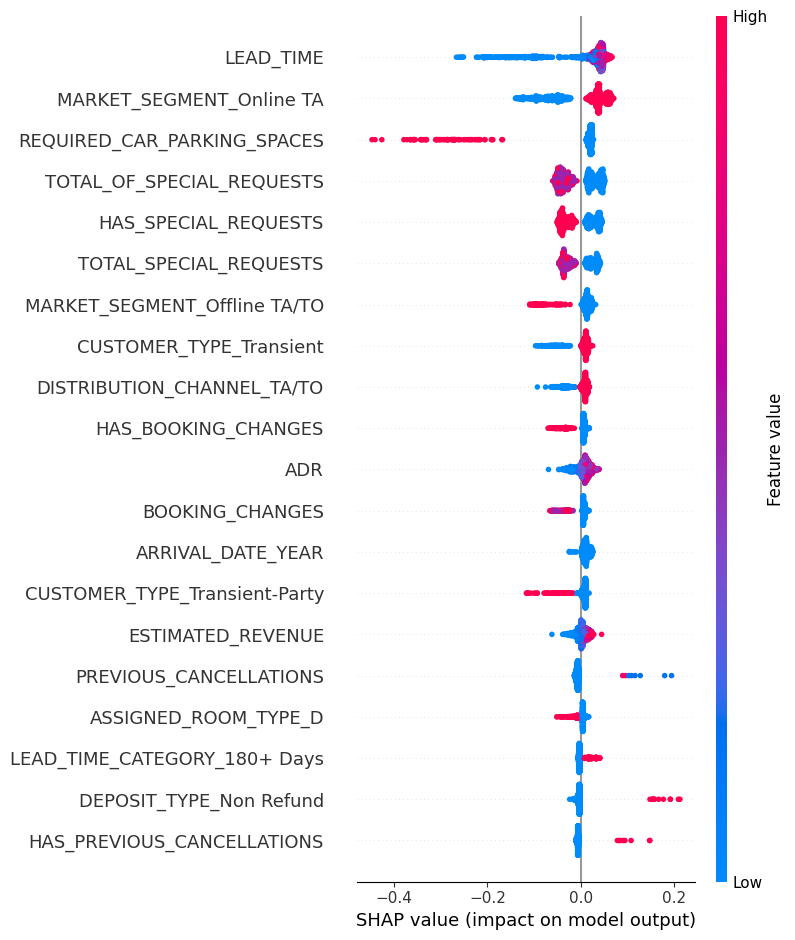

In [ ]:
# SHAP Summary Plot - using a sample for faster computation

X_shap = X_test.sample(n=1000, random_state=42)

print("SHAP sample shape:", X_shap.shape)

shap_values = explainer.shap_values(X_shap)

# For binary classification, use SHAP values for class 1
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values

shap.summary_plot(
    shap_values_plot,
    X_shap,
    show=True
)

In [ ]:
import shap

# Create SHAP explainer using the loaded Random Forest
explainer = shap.TreeExplainer(rf)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


SHAP sample shape: (1000, 81)


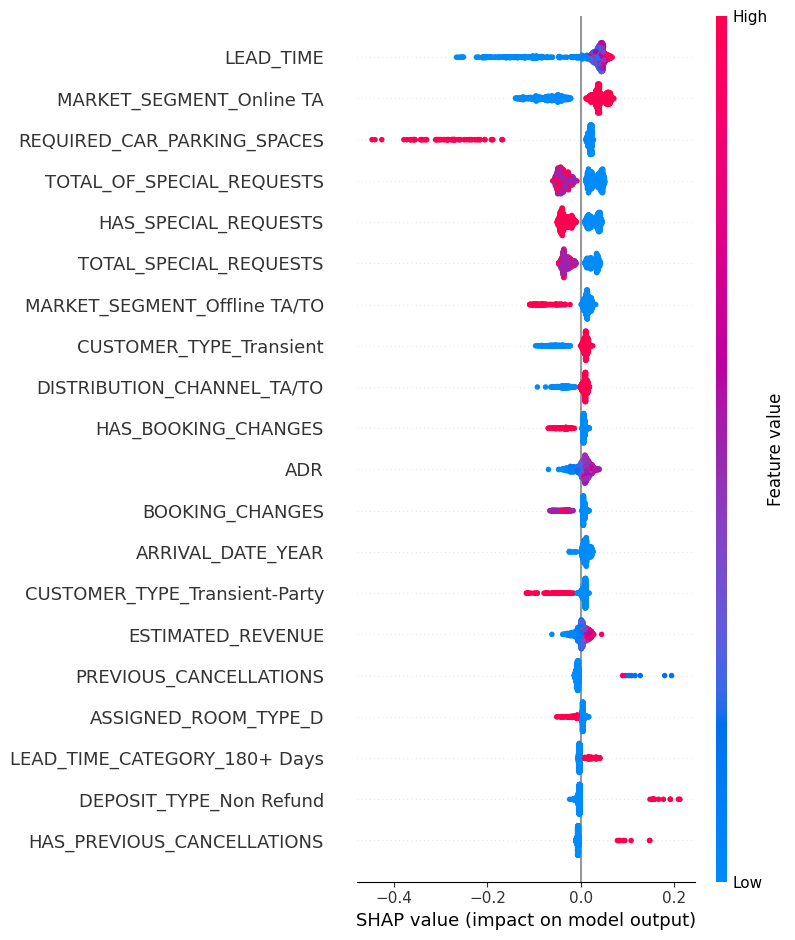

In [ ]:
# SHAP Summary Plot - using a sample for faster computation

X_shap = X_test.sample(n=1000, random_state=42)

print("SHAP sample shape:", X_shap.shape)

shap_values = explainer.shap_values(X_shap)

# For binary classification, use SHAP values for class 1
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values

shap.summary_plot(
    shap_values_plot,
    X_shap,
    show=True
)

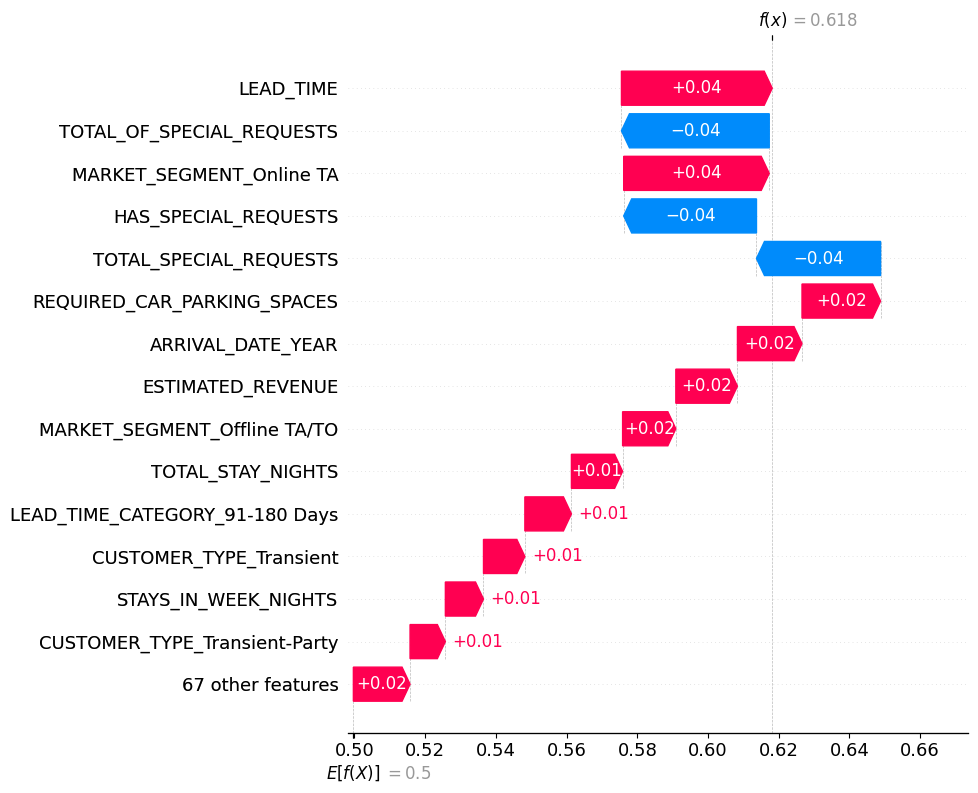

In [ ]:
# SHAP Individual Prediction Explanation

# Select one booking from the SHAP sample
booking_index = 0

single_booking = X_shap.iloc[[booking_index]]

# Calculate SHAP values for this booking
single_shap_values = explainer.shap_values(single_booking)

# For binary classification, use class 1
if isinstance(single_shap_values, list):
    single_shap_plot = single_shap_values[1][0]
else:
    single_shap_plot = single_shap_values[0]

# Waterfall explanation
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value[1],
    single_shap_plot,
    feature_names=single_booking.columns,
    max_display=15
)

In [ ]:

# TravelIQ: Save training-based feature defaults

import os
import joblib

# Calculate medians from training features only
feature_medians = X_train.median(numeric_only=True)

# Keep the same feature order as the trained model
feature_medians = feature_medians.reindex(X_train.columns)

# Verify no feature defaults are missing
missing_defaults = feature_medians[feature_medians.isna()].index.tolist()

print("Training features:", len(X_train.columns))
print("Missing median defaults:", missing_defaults)

# Save defaults for the Streamlit app
os.makedirs("../models", exist_ok=True)

joblib.dump(
    feature_medians,
    "../models/feature_medians.pkl"
)

print("Saved: models/feature_medians.pkl")


Training features: 81
Missing median defaults: []
Saved: models/feature_medians.pkl


In [95]:

import pandas as pd

# Load the saved prediction results
df = pd.read_csv("../data/final_predictions.csv")

# Select high-risk bookings
high_risk = df[df["RISK_CATEGORY"] == "High Risk"].copy()

# Calculate business metrics from actual saved data
revenue_at_risk = (
    high_risk["ADR"] *
    (
        high_risk["STAYS_IN_WEEKEND_NIGHTS"]
        + high_risk["STAYS_IN_WEEK_NIGHTS"]
    )
).sum()

avg_lead_time = high_risk["LEAD_TIME"].mean()
avg_adr = df["ADR"].mean()

avg_stay = (
    df["STAYS_IN_WEEKEND_NIGHTS"]
    + df["STAYS_IN_WEEK_NIGHTS"]
).mean()

print("===== TravelIQ Dashboard Verification =====")
print("Total prediction records:", len(df))
print("High-risk bookings:", len(high_risk))
print(f"Revenue at risk: {revenue_at_risk:,.2f}")
print(f"Average lead time (high-risk): {avg_lead_time:.2f} days")
print(f"Average ADR (all records): {avg_adr:.2f}")
print(f"Average stay (all records): {avg_stay:.2f} nights")

print("\nTop high-risk market segments:")
market_cols = [
    col for col in high_risk.columns
    if col.startswith("MARKET_SEGMENT_")
]

if market_cols:
    market_counts = high_risk[market_cols].sum().sort_values(ascending=False)
    print(market_counts.head())
else:
    print("Encoded market-segment columns nahi mile.")


===== TravelIQ Dashboard Verification =====
Total prediction records: 25556
High-risk bookings: 6442
Revenue at risk: 3,937,088.65
Average lead time (high-risk): 139.01 days
Average ADR (all records): 128.74
Average stay (all records): 3.81 nights

Top high-risk market segments:
MARKET_SEGMENT_Online TA        6135
MARKET_SEGMENT_Groups            184
MARKET_SEGMENT_Offline TA/TO      83
MARKET_SEGMENT_Direct             35
MARKET_SEGMENT_Corporate           5
dtype: int64
